In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

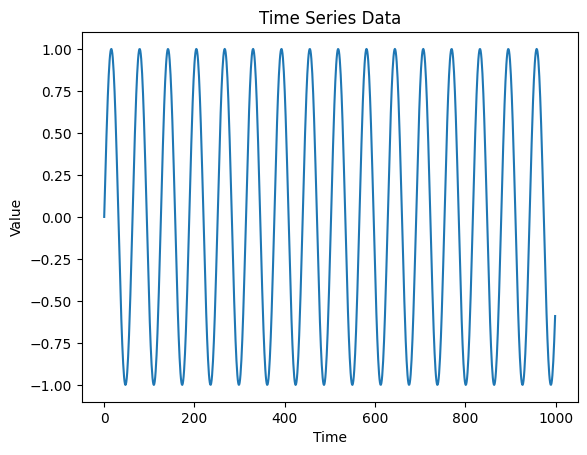

In [ ]:
time = np.arange(0, 100, 0.1)

data = np.sin(time)

plt.plot(data)
plt.title("Time Series Data")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [ ]:
X = []
y = []

for i in range(len(data) - 10):
    X.append(data[i:i+10])
    y.append(data[i+10])

X = np.array(X)
y = np.array(y)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (990, 10, 1)
Output Shape: (990,)


In [ ]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (792, 10, 1)
Testing Data: (198, 10, 1)


In [ ]:
model = Sequential([
    SimpleRNN(50, activation='tanh',
              input_shape=(10, 1)),
    Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(
    optimizer='adam',
    loss='mse'
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0961 - val_loss: 0.0074
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0080 - val_loss: 0.0039
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0037 - val_loss: 0.0028
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0021 - val_loss: 0.0016
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0013 - val_loss: 9.7577e-04
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.2283e-04 - val_loss: 6.2355e-04
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.3214e-04 - val_loss: 4.0605e-04
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.2174e-04 - val_loss: 2.3616e-04
Epoch 9/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.0494e-04 - val_loss: 2.0810e-04
Epoch 10/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6025e-04 - val_loss: 1.4652e-04


In [ ]:
loss = model.evaluate(X_test, y_test)

print("Test Loss:", loss)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6082e-04 
Test Loss: 0.00016082002548500896


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


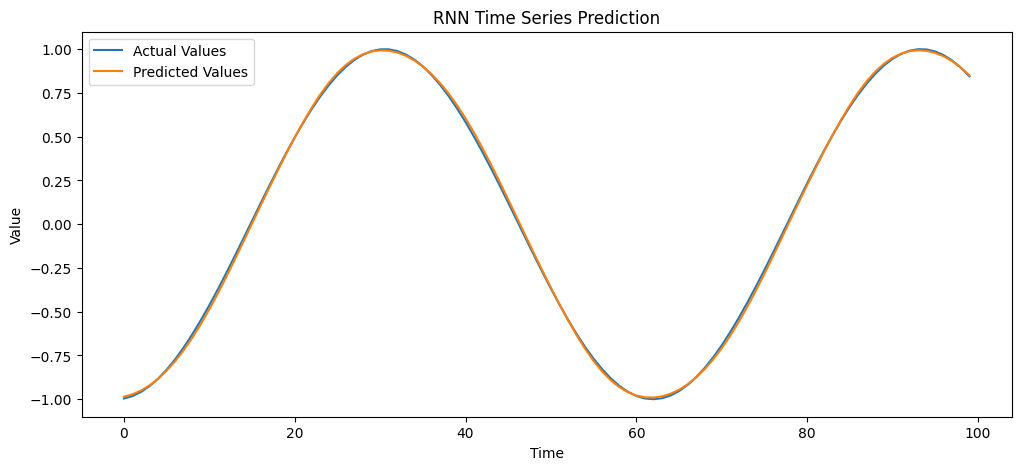

In [ ]:
predictions = model.predict(X_test)

plt.figure(figsize=(12, 5))

plt.plot(y_test[:100], label='Actual Values')
plt.plot(predictions[:100], label='Predicted Values')

plt.title("RNN Time Series Prediction")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()